# NutriWise – Multivariate Regression Models

## Mission and use case
NutriWise aims to improve nutrition in African farming communities. The model predicts how much food energy is available to a farm household, in kilocalories per adult per day (`Food_Availability_kCal_MAE_day`).

**Who would use it and what for:** NGO field officers and agricultural extension workers could enter facts that are quick to collect, such as household size, land and livestock, to get a first estimate of which households may be short of food. They could then visit those households first.

> **Important interpretation:** the target is the food energy *available* to a household, per male adult equivalent. It is not what any one person ate, and it is not a recommended calorie target.

## Dataset
The data comes from the Rural Household Multiple Indicator Survey (RHoMIS), a survey of farm households published under a public-domain (CC0) licence: [RHoMIS on Harvard Dataverse](https://doi.org/10.7910/DVN/9M6EHS). The full file covers 21 countries. `rhomis_africa.csv` keeps only the 11 African ones (Burkina Faso, Burundi, DRC, Ethiopia, Ghana, Kenya, Malawi, Mali, Tanzania, Uganda and Zambia), surveyed from 2015 to 2018. Place it in the same folder as this notebook.

This notebook:
1. inspects and cleans the data;
2. explores relationships using plots;
3. prepares numeric and categorical features without test-data leakage;
4. trains and compares four regression models;
5. tunes `SGDRegressor` and plots its train/test loss curve;
6. saves the best complete preprocessing-and-model pipeline as `best_model.pkl`.

In [1]:
# 1. Imports and load dataset
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np  # pyright: ignore[reportMissingImports]
import pandas as pd # pyright: ignore[reportMissingModuleSource]
import matplotlib.pyplot as plt # pyright: ignore[reportMissingModuleSource]
import seaborn as sns # pyright: ignore[reportMissingModuleSource]
import joblib # pyright: ignore[reportMissingImports]

from sklearn.model_selection import train_test_split, ParameterGrid # pyright: ignore[reportMissingModuleSource]
from sklearn.compose import ColumnTransformer # pyright: ignore[reportMissingModuleSource]
from sklearn.pipeline import Pipeline # pyright: ignore[reportMissingModuleSource]
from sklearn.preprocessing import OneHotEncoder, StandardScaler # pyright: ignore[reportMissingModuleSource]
from sklearn.impute import SimpleImputer # pyright: ignore[reportMissingModuleSource]
from sklearn.linear_model import SGDRegressor, LinearRegression # pyright: ignore[reportMissingModuleSource]
from sklearn.tree import DecisionTreeRegressor # pyright: ignore[reportMissingModuleSource]
from sklearn.ensemble import RandomForestRegressor # pyright: ignore[reportMissingModuleSource]
from sklearn.metrics import mean_squared_error # pyright: ignore[reportMissingModuleSource]
from sklearn.base import clone # pyright: ignore[reportMissingModuleSource]

DATA_PATH = Path("rhomis_africa.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place rhomis_africa.csv in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (11010, 53)


,ID_PROJ,ID_COUNTRY,YEAR,ITERATION,SURVEY_ID,ID_HH,GPS_LAT,GPS_LON,GPS_ALT,Country,...,value_livestock_prod_consumed_USD_PPP_pHH_Yr,Market_Orientation,Livestock_Orientation,Food_Availability_kCal_MAE_day,Food_Self_Sufficiency_kCal_MAE_day,NrofMonthsWildFoodCons,GHGEmissions,Gender_MaleControl,Gender_FemaleControl,NFertInput
0,CFM,TZ,2015,1,TZ_CFM_2015,TZ_2015_CFM_1_1,NaN,NaN,NaN,Tanzania,...,0.000000,1.000000,0.049505,3650.565755,0.000000,0,NaN,0.000000,1.000000,NaN
1,CFM,TZ,2015,1,TZ_CFM_2015,TZ_2015_CFM_2_1,NaN,NaN,NaN,Tanzania,...,0.000000,1.000000,0.000000,3632.448997,0.000000,4,143.934000,0.499999,0.500001,75.0
2,CFM,TZ,2015,1,TZ_CFM_2015,TZ_2015_CFM_3_1,NaN,NaN,NaN,Tanzania,...,0.000000,1.000000,0.129870,5314.779021,1750.000000,1,3248.700905,1.000000,0.000000,20.0
3,CFM,TZ,2015,1,TZ_CFM_2015,TZ_2015_CFM_4_1,NaN,NaN,NaN,Tanzania,...,0.000000,NaN,NaN,257.234727,257.234727,0,887.156057,NaN,NaN,15.0
4,CFM,TZ,2015,1,TZ_CFM_2015,TZ_2015_CFM_5_1,NaN,NaN,NaN,Tanzania,...,23.102694,0.931377,0.695041,925.310354,22.070240,0,14275.030776,1.000000,0.000000,50.0


## 2. Inspect data quality

The file contains 11,010 households and 53 columns, with a mix of numeric and categorical data. This is above the assignment minimum of 1,000 rows and 8 feature columns.

The main problems found are:
- **Missing values:** the target is missing for 66 households. Among the chosen inputs, `Gender_FemaleControl` is missing for 1,668, `Head_EducationLevel` for 399, `LandCultivated` for 228 and `HouseholdType` for 17.
- **Extreme values:** the target reaches 82 billion kcal per day, one household is recorded with 3,984 members, and `LandCultivated` reaches 1,175. These look like data errors.
- **Inconsistent text:** `Head_EducationLevel` spells the same answer in several ways, for example `no_school`, `No_school` and `no school`.
- **Real zeros:** 0 in `LivestockHoldings` means the household has no livestock, so zeros are kept and not treated as missing.

In [2]:


print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\nMissing-value percentage:")
display((df.isna().mean() * 100).round(1).to_frame("missing_percent"))


Shape: (11010, 53)

Data types:


,dtype
ID_PROJ,str
ID_COUNTRY,str
YEAR,int64
ITERATION,int64
SURVEY_ID,str
ID_HH,str
GPS_LAT,float64
GPS_LON,float64
GPS_ALT,float64
Country,str



Missing values:


,missing_count
ID_PROJ,0
ID_COUNTRY,0
YEAR,0
ITERATION,0
SURVEY_ID,0
ID_HH,0
GPS_LAT,1990
GPS_LON,1990
GPS_ALT,1990
Country,0



Missing-value percentage:


,missing_percent
ID_PROJ,0.0
ID_COUNTRY,0.0
YEAR,0.0
ITERATION,0.0
SURVEY_ID,0.0
ID_HH,0.0
GPS_LAT,18.1
GPS_LON,18.1
GPS_ALT,18.1
Country,0.0


## 3. Feature selection and cleaning

### Selected target
- `Food_Availability_kCal_MAE_day`: food energy available per male adult equivalent per day, in kilocalories.

### Selected input features (10)
- Numeric: `HHsizemembers`, `LandCultivated`, `LivestockHoldings`, `NrofMonthsFoodInsecure`, `NrofMonthsWildFoodCons`, `Gender_FemaleControl`
- Categorical: `Country`, `HouseholdType`, `Head_EducationLevel`, `HFIAS_status`

### Columns dropped and why
The other 42 columns are not used. The main reasons are:
- **Leakage:** `Food_Self_Sufficiency_kCal_MAE_day` and the income, sales and production-value columns are closely tied to how the target is calculated, so using them would give away the answer.
- **Identifiers and location:** IDs, survey codes and GPS columns identify a record and do not describe the household.
- **Too many missing values:** `PPI_Likelihood` is missing for every household in Burundi and DRC, and `Altitude` is missing for all of Malawi. `FIES_Score` is empty, and `Region`, `GHGEmissions` and `NFertInput` are mostly missing.

### Cleaning decisions
| Column | Kept range | Reason |
|---|---|---|
| Target | 100 to 50,000 kcal | Below 100 a household could not survive, and values above 50,000 are not realistic for one adult per day |
| `HHsizemembers` | 1 to 30 | A household needs at least one person, and very large values are likely errors |
| `LandCultivated` | 0 to 50 | 99% of households have 25 or less; missing values are kept and imputed |
| `LivestockHoldings` | 0 to 50 | 95% of households have about 25 or less |

This removes 1,465 of the 10,944 households that have a target and leaves 9,479. Households without a target are removed because the target is never imputed. Categories stay as text and are one-hot encoded; missing inputs are imputed inside the pipeline.

### Features that matter most
Shuffling one feature at a time in the test set shows how much the final random forest's R² falls. The largest drops were `HHsizemembers` (0.23), `LandCultivated` (0.14), `LivestockHoldings` (0.09), `Gender_FemaleControl` (0.06) and `Country` (0.05). `HouseholdType` made almost no difference (0.001).

In [3]:
TARGET = "Food_Availability_kCal_MAE_day"

numeric_features = [
    "HHsizemembers", "LandCultivated", "LivestockHoldings",
    "NrofMonthsFoodInsecure", "NrofMonthsWildFoodCons", "Gender_FemaleControl"
]
categorical_features = ["Country", "HouseholdType", "Head_EducationLevel", "HFIAS_status"]
features = numeric_features + categorical_features

required = features + [TARGET]
missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Remove rows with a missing target; never impute the target.
model_df = df[required].copy()
model_df = model_df.dropna(subset=[TARGET])

# Remove impossible/invalid negative target values if any.
model_df = model_df[model_df[TARGET] >= 0].copy()

rows_before = len(model_df)

# Keep only realistic calorie values
model_df = model_df[model_df[TARGET].between(100, 50000)]

# Keep only realistic household sizes
model_df = model_df[model_df["HHsizemembers"].between(1, 30)]

# Keep realistic land sizes, and rows where land is missing
land = model_df["LandCultivated"]
model_df = model_df[land.between(0, 50) | land.isna()]

# Keep only realistic livestock holdings
model_df = model_df[model_df["LivestockHoldings"].between(0, 50)].copy()

print("Rows before:", rows_before, "| after:", len(model_df), "| removed:", rows_before - len(model_df))

# Keep categories as text, with missing values as np.nan so SimpleImputer can fill them.
for col in categorical_features:
    model_df[col] = model_df[col].astype(object).where(model_df[col].notna(), np.nan)

X = model_df[features]
y = model_df[TARGET].astype(float)

print(f"Rows available for modelling: {len(model_df):,}")
print(f"Number of input features: {len(features)}")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target:", TARGET)
assert len(model_df) >= 1000, "Dataset must contain at least 1,000 usable rows."
assert len(features) >= 8, "At least 8 input features are required."


Rows before: 10944 | after: 9479 | removed: 1465
Rows available for modelling: 9,479
Number of input features: 10
Numeric features: ['HHsizemembers', 'LandCultivated', 'LivestockHoldings', 'NrofMonthsFoodInsecure', 'NrofMonthsWildFoodCons', 'Gender_FemaleControl']
Categorical features: ['Country', 'HouseholdType', 'Head_EducationLevel', 'HFIAS_status']
Target: Food_Availability_kCal_MAE_day


## 4. Exploratory data analysis

These plots show how the numeric features relate to food availability and how the target is distributed. Each plot is followed by what it shows and the decision made because of it.

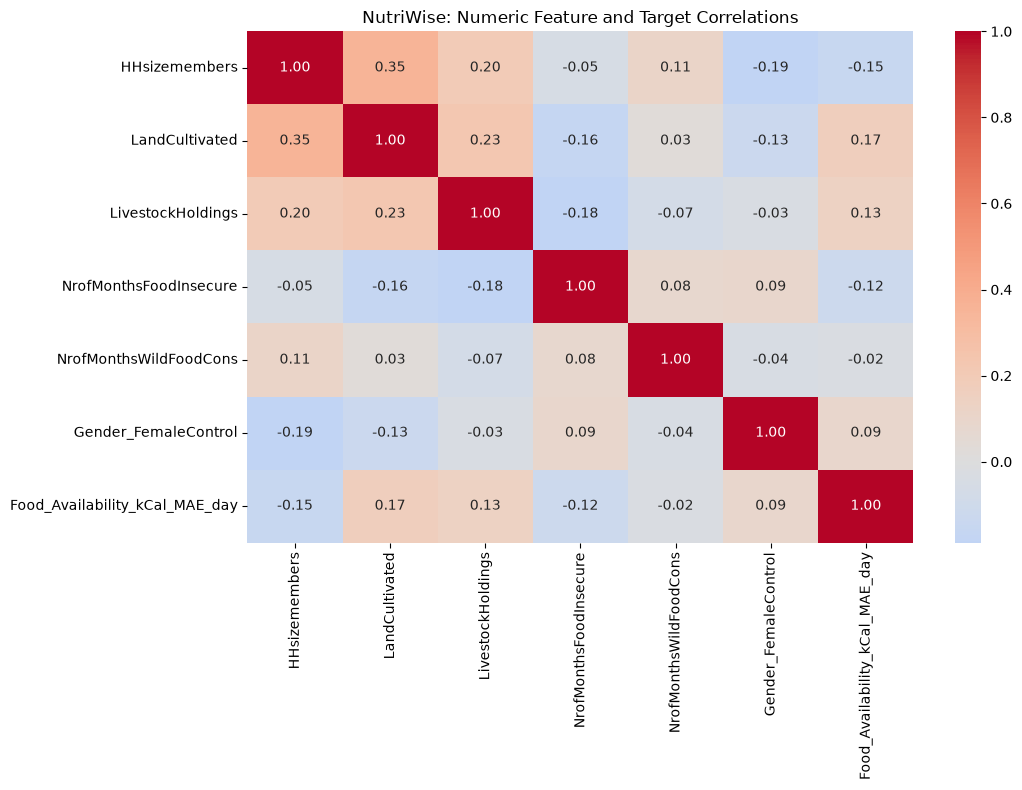

In [4]:
# Plot 1: correlation heatmap (numeric columns only)
numeric_for_corr = model_df[numeric_features + [TARGET]].copy()
corr = numeric_for_corr.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("NutriWise: Numeric Feature and Target Correlations")
plt.tight_layout()
plt.show()

**What it shows:** No numeric feature is strongly correlated with the target. The strongest are `LandCultivated` (0.17), `HHsizemembers` (-0.15), `LivestockHoldings` (0.13) and `NrofMonthsFoodInsecure` (-0.12), and the inputs overlap little with each other (the highest is 0.35, between land and household size).

**Decision:** Because no single feature is enough and none are duplicates, all six numeric features are kept, categorical features are added, and tree models are tested alongside the linear ones in case the relationships are not straight lines.

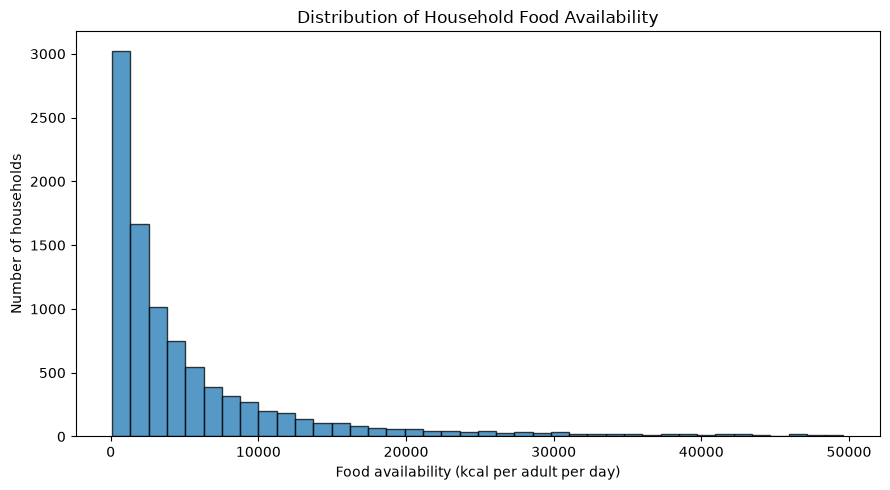

In [5]:
# Plot 2: target distribution
plt.figure(figsize=(9, 5))
plt.hist(y, bins=40, edgecolor="black", alpha=0.75)
plt.xlabel("Food availability (kcal per adult per day)")
plt.ylabel("Number of households")
plt.title("Distribution of Household Food Availability")
plt.tight_layout()
plt.show()

**What it shows:** The target is strongly right-skewed (skewness about 2.7). Half of the households are below about 2,600 kcal, but the mean is about 5,600 because a small number reach almost 50,000.

**Decision:** Because MSE squares large errors, extreme values were limited to 100–50,000 kcal. The remaining long tail is one reason the MSE is still high, so a log transform of the target is a possible next step.

## 5. Required scatter plots: before and after

`LandCultivated` is the numeric feature with the largest absolute correlation with the target (0.17). The first plot shows the raw relationship. The second adds a fitted one-feature linear regression line, which is only for visualization and is not one of the four models being compared.

Most correlated numeric feature: LandCultivated
Correlation with target: 0.166


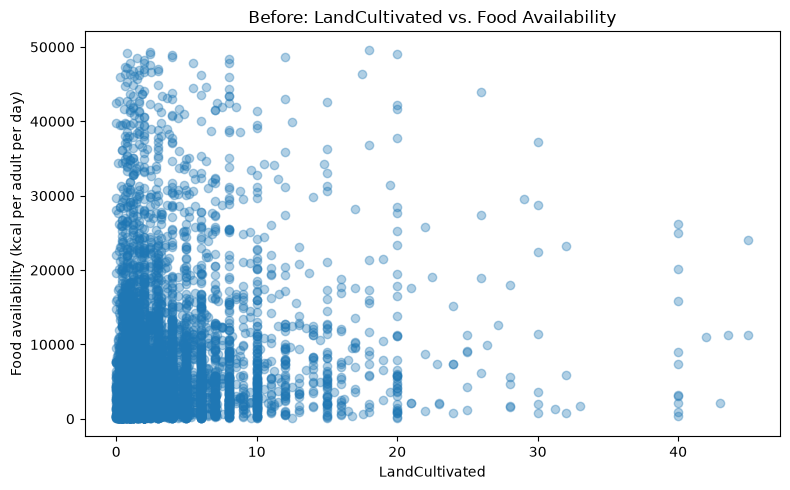

In [6]:
# Find numeric feature most correlated with the target.
target_corr = corr[TARGET].drop(TARGET).dropna()
best_scatter_feature = target_corr.abs().idxmax()
print("Most correlated numeric feature:", best_scatter_feature)
print("Correlation with target:", round(target_corr[best_scatter_feature], 3))

scatter_data = model_df[[best_scatter_feature, TARGET]].dropna()

# Scatter plot before fitting
plt.figure(figsize=(8, 5))
plt.scatter(scatter_data[best_scatter_feature], scatter_data[TARGET], alpha=0.35)
plt.xlabel(best_scatter_feature)
plt.ylabel("Food availability (kcal per adult per day)")
plt.title(f"Before: {best_scatter_feature} vs. Food Availability")
plt.tight_layout()
plt.show()

**What it shows:** Most households cultivate little land, and those with similar land have very different food availability, from almost nothing to about 50,000 kcal. The relationship is positive but weak.

**Decision:** Land is kept because it is the most correlated feature, but it is combined with the other nine features because it cannot explain food availability alone.

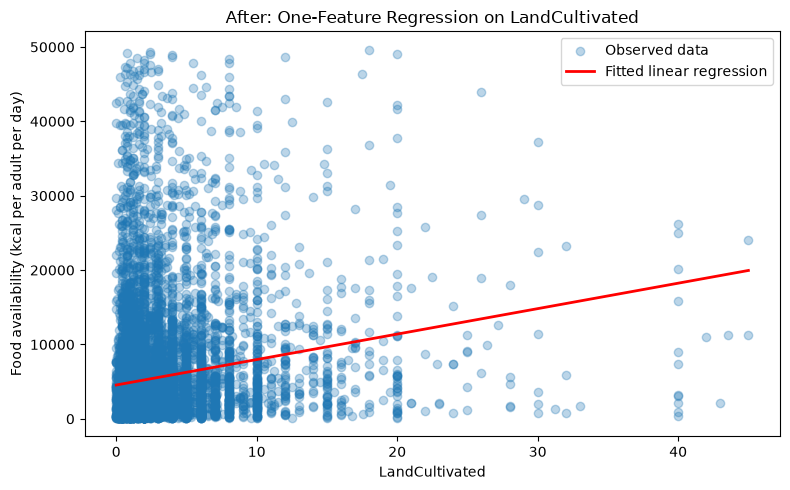

In [7]:
# Fit a one-feature regression line for visualization only
one_feature_model = LinearRegression()
one_feature_model.fit(scatter_data[[best_scatter_feature]], scatter_data[TARGET])

x_line = np.linspace(
    scatter_data[best_scatter_feature].min(),
    scatter_data[best_scatter_feature].max(),
    200
).reshape(-1, 1)
y_line = one_feature_model.predict(x_line)

plt.figure(figsize=(8, 5))
plt.scatter(scatter_data[best_scatter_feature], scatter_data[TARGET], alpha=0.30, label="Observed data")
plt.plot(x_line, y_line, color="red", linewidth=2, label="Fitted linear regression")
plt.xlabel(best_scatter_feature)
plt.ylabel("Food availability (kcal per adult per day)")
plt.title(f"After: One-Feature Regression on {best_scatter_feature}")
plt.legend()
plt.tight_layout()
plt.show()

**What it shows:** The line rises from about 4,500 kcal with no land by about 342 kcal for each extra unit of land. It explains only about 3% of the variation (R² = 0.03), and the points are widely spread around it.

**Decision:** A single straight line is not enough, so multivariate and non-linear models are compared.

## 6. Train/test split and preprocessing

We use an 80/20 train/test split. Numeric columns are median-imputed and standardized. Categorical columns are imputed with their most frequent value and one-hot encoded.

**Leakage prevention:** the preprocessing transformer is fitted only on training data. The test set is transformed using the already-fitted training transformer.


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocess, numeric_features),
    ("categorical", categorical_preprocess, categorical_features)
])

# Fit only on training rows.
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training rows:", X_train_processed.shape[0])
print("Test rows:", X_test_processed.shape[0])
print("Processed feature count:", X_train_processed.shape[1])


Training rows: 7583
Test rows: 1896
Processed feature count: 61


## 7. Tune SGDRegressor using a validation split

`SGDRegressor` is the gradient-descent model. We tune:
- `eta0`: initial learning rate;
- `alpha`: L2 regularization strength;
- `epochs`: number of passes through the training subset.

A validation subset is held out from the training data for choosing these settings. The final test set is reserved for the common model comparison. The loss curve below will then show train and test MSE per epoch, as required by the assignment.


In [9]:
# Split the original training partition again for hyperparameter selection.
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=21
)

tune_preprocessor = clone(preprocessor)
X_subtrain_p = tune_preprocessor.fit_transform(X_subtrain)
X_val_p = tune_preprocessor.transform(X_val)

param_grid = {
    "eta0": [0.0001, 0.0005, 0.001, 0.005],
    "alpha": [0.00001, 0.0001, 0.001, 0.01, 0.1],
    "epochs": [10, 25, 50, 100, 200]
}

tuning_results = []
rng = np.random.default_rng(42)

for params in ParameterGrid(param_grid):
    candidate = SGDRegressor(
        loss="squared_error",
        penalty="l2",
        alpha=params["alpha"],
        learning_rate="constant",
        eta0=params["eta0"],
        max_iter=1,
        tol=None,
        random_state=42
    )

    for epoch in range(params["epochs"]):
        order = rng.permutation(len(y_subtrain))
        candidate.partial_fit(X_subtrain_p[order], y_subtrain.iloc[order])

    val_pred = candidate.predict(X_val_p)
    val_mse = mean_squared_error(y_val, val_pred)
    tuning_results.append({**params, "validation_mse": val_mse})

tuning_table = pd.DataFrame(tuning_results).sort_values("validation_mse")
display(tuning_table.head(10))

best_params = tuning_table.iloc[0].to_dict()
best_eta0 = float(best_params["eta0"])
best_alpha = float(best_params["alpha"])
best_epochs = int(best_params["epochs"])

print("Best SGD settings:")
print({"eta0": best_eta0, "alpha": best_alpha, "epochs": best_epochs})


,alpha,epochs,eta0,validation_mse
74,0.01000,100,0.0010,5.043832e+07
78,0.01000,200,0.0010,5.060853e+07
2,0.00001,10,0.0010,5.071153e+07
65,0.01000,25,0.0005,5.073351e+07
6,0.00001,25,0.0010,5.081952e+07
73,0.01000,100,0.0005,5.082991e+07
37,0.00010,200,0.0005,5.083444e+07
76,0.01000,200,0.0001,5.083761e+07
56,0.00100,200,0.0001,5.084634e+07
32,0.00010,100,0.0001,5.085423e+07


Best SGD settings:
{'eta0': 0.001, 'alpha': 0.01, 'epochs': 100}


## 8. Train SGDRegressor with `partial_fit` and plot its loss curve

The preprocessor is now fitted on the complete training partition only. We train one epoch at a time with `partial_fit`, recording train and test MSE after every epoch.


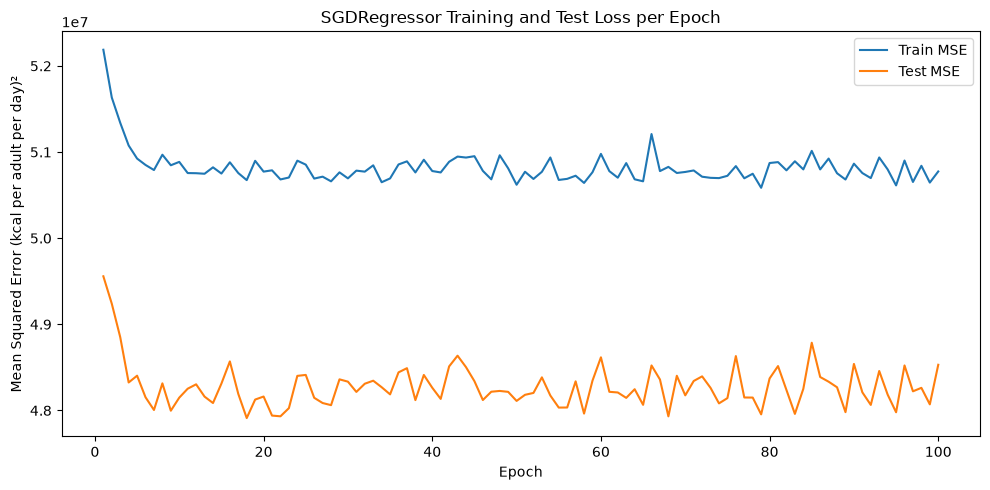

In [10]:
# Refit preprocessing on all training data only.
final_preprocessor = clone(preprocessor)
X_train_p = final_preprocessor.fit_transform(X_train)
X_test_p = final_preprocessor.transform(X_test)

sgd_model = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    alpha=best_alpha,
    learning_rate="constant",
    eta0=best_eta0,
    max_iter=1,
    tol=None,
    random_state=42
)

train_losses = []
test_losses = []
rng = np.random.default_rng(123)

for epoch in range(best_epochs):
    order = rng.permutation(len(y_train))
    sgd_model.partial_fit(X_train_p[order], y_train.iloc[order])

    train_pred_epoch = sgd_model.predict(X_train_p)
    test_pred_epoch = sgd_model.predict(X_test_p)

    train_losses.append(mean_squared_error(y_train, train_pred_epoch))
    test_losses.append(mean_squared_error(y_test, test_pred_epoch))

plt.figure(figsize=(10, 5))
plt.plot(range(1, best_epochs + 1), train_losses, label="Train MSE")
plt.plot(range(1, best_epochs + 1), test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (kcal per adult per day)²")
plt.title("SGDRegressor Training and Test Loss per Epoch")
plt.legend()
plt.tight_layout()
plt.show()

sgd_pipeline = Pipeline(steps=[
    ("preprocessor", final_preprocessor),
    ("model", sgd_model)
])


## 9. Train and compare all four regression models

All four models use the same train/test split and the same training-fitted preprocessing. We compare both training MSE and test MSE. Lower test MSE indicates better predictive performance on this held-out test set.


In [11]:
models = {
    "SGDRegressor": sgd_pipeline,
    "LinearRegression": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", LinearRegression())
    ]),
    "DecisionTreeRegressor": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", DecisionTreeRegressor(random_state=42, min_samples_leaf=5))
    ]),
    "RandomForestRegressor": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            min_samples_leaf=10,
            n_jobs=-1
        ))
    ])
}

results = []
for name, model in models.items():
    if name != "SGDRegressor":
        model.fit(X_train, y_train)

    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)

    results.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, train_prediction),
        "Test MSE": mean_squared_error(y_test, test_prediction)
    })

results_df = pd.DataFrame(results).sort_values("Test MSE").reset_index(drop=True)
display(results_df.style.format({
    "Train MSE": "{:,.2f}",
    "Test MSE": "{:,.2f}"
}))

best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]

print(f"Best model based on the lowest test MSE: {best_model_name}")
print(f"Lowest test MSE: {results_df.loc[0, 'Test MSE']:,.2f}")


,Model,Train MSE,Test MSE
0,RandomForestRegressor,"35,205,877.09","44,627,858.79"
1,LinearRegression,"50,179,948.33","47,959,388.61"
2,SGDRegressor,"50,774,571.80","48,530,295.32"
3,DecisionTreeRegressor,"27,527,030.68","58,861,006.92"


Best model based on the lowest test MSE: RandomForestRegressor
Lowest test MSE: 44,627,858.79


## 10. Interpret the model comparison

| Model | Train MSE | Test MSE |
|---|---|---|
| **RandomForestRegressor** | 35,205,877 | **44,627,859** |
| LinearRegression | 50,179,948 | 47,959,389 |
| SGDRegressor | 50,774,572 | 48,530,295 |
| DecisionTreeRegressor | 27,527,031 | 58,861,007 |

**Best model:** `RandomForestRegressor` has the lowest test MSE, so it is saved for the API.

- **Random forest:** it combines many trees, so it can capture non-linear effects and differences between countries. It overfits moderately. `min_samples_leaf=10` limits this and keeps the saved file at about 2 MB.
- **Decision tree:** it has the lowest train MSE but the highest test MSE, so it overfits the most. It learned noise from this very variable survey data.
- **Linear models:** the two are almost equal, as expected for the same kind of model fitted in two ways. They do not overfit, but straight lines miss part of the pattern because the features are only weakly linear with the target.

**Is the loss high or low?** It is high. The test RMSE is about 6,680 kcal and R² is about 0.26, so the model explains about a quarter of the variation. Predicting the training mean for everyone gives a test MSE of about 60.0 million, so the model is better than guessing but not precise enough for decisions about a single household.

**Effect of the dataset:** the target is skewed, the survey answers are self-reported, some inputs are missing, and some countries have few households (Malawi 123 and Uganda 127). To reduce the loss, the next steps would be a log transform of the target, merging the repeated education spellings and adding informative features such as crops grown.

## 11. Save the best complete model pipeline

The saved pipeline includes preprocessing and the fitted estimator. This is important because the API must apply exactly the same imputing, scaling and categorical encoding steps to new user inputs.


In [12]:
MODEL_PATH = Path("../API/best_model.pkl")
joblib.dump(best_model, MODEL_PATH, compress=3)
print(f"Saved best model pipeline to: {MODEL_PATH.resolve()}")


def load_and_predict(row, model_path=MODEL_PATH):
    """Load the saved pipeline and predict the target for a one-row DataFrame."""
    loaded_model = joblib.load(model_path)
    return float(loaded_model.predict(row)[0])


# Demonstrate the function on one held-out test row.
one_test_row = X_test.iloc[[0]]
actual_value = y_test.iloc[0]
predicted_value = load_and_predict(one_test_row)

print(f"Actual food availability: {actual_value:,.1f} kcal per adult per day")
print(f"Predicted food availability: {predicted_value:,.1f} kcal per adult per day")

Saved best model pipeline to: C:\Users\HP\Desktop\Summative---Regression-Analysis\summative\API\best_model.pkl


Actual food availability: 6,099.0 kcal per adult per day
Predicted food availability: 5,244.2 kcal per adult per day


## 12. Limitations and responsible use

1. The data is an African dataset: RHoMIS surveys of farm households in 11 countries (Burkina Faso, Burundi, DRC, Ethiopia, Ghana, Kenya, Malawi, Mali, Tanzania, Uganda and Zambia), collected from 2015 to 2018. Rwanda is not included, so the model needs validation on Rwandan data before it is used there.
2. The countries are not equally represented. Burkina Faso and Tanzania make up about half of the rows, while Uganda and Malawi have fewer than 160 each, so predictions may be less reliable for the smaller groups.
3. `Food_Availability_kCal_MAE_day` estimates the calories available per adult per day in a household. It does not measure what any one person ate.
4. The survey answers are self-reported and can contain recall and reporting errors. The data also has missing values and extreme outliers.
5. This model is for a machine-learning coursework demonstration and nutrition awareness, not diagnosis or personalized medical advice.
6. A low MSE does not establish that the model is suitable for real-world decisions. Further validation and domain expertise would be required first.